# IPL Ball-by-Ball Data: Practice Questions
**Libraries:** pandas, numpy, matplotlib, seaborn

- 20 beginner questions
- 5 medium questions

**Dataset notes**
- `match_won_by` holds the winning team's name.
- `valid_ball` is 0 for wides and no-balls, so filter on it when counting balls faced.
- Team names changed over the years (e.g. Delhi Daredevils became Delhi Capitals).

In [44]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("IPL.csv")

/tmp/ipykernel_1678/3205794338.py:5: DtypeWarning: Columns (27,28,29,30,42,45,46,47,50) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("IPL.csv")


---
## Beginner Level: Pandas Basics

**Q1.** Display the first 5 and last 5 rows, then print the shape, column names and data types of the dataset.

In [45]:
# Your code here
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.dtypes)

   match_id        date match_type             event_name  innings  \
0    335982  2008-04-18        T20  Indian Premier League        1   
1    335982  2008-04-18        T20  Indian Premier League        1   
2    335982  2008-04-18        T20  Indian Premier League        1   
3    335982  2008-04-18        T20  Indian Premier League        1   
4    335982  2008-04-18        T20  Indian Premier League        1   

            batting_team                 bowling_team  over  ball  ball_no  \
0  Kolkata Knight Riders  Royal Challengers Bangalore     0     1      0.1   
1  Kolkata Knight Riders  Royal Challengers Bangalore     0     2      0.2   
2  Kolkata Knight Riders  Royal Challengers Bangalore     0     3      0.3   
3  Kolkata Knight Riders  Royal Challengers Bangalore     0     3      0.3   
4  Kolkata Knight Riders  Royal Challengers Bangalore     0     4      0.4   

   ... team_balls  team_wicket  new_batter  power_surge_start batter_runs  \
0  ...          1            0   

**Q2.** How many unique matches (`match_id`) and how many unique venues are in the data?

In [46]:
# Your code here
n_matches = df["match_id"].nunique()
n_venues = df["venue"].nunique()
print(n_matches)
print(n_venues)

1243
60


**Q3.** Which columns have missing values? Show the count of nulls for each, sorted from highest to lowest.

In [47]:
# Your code here
nulls = df.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(nulls)

power_surge_start    295732
team_reviewed        294742
review_batter        294742
review_decision      294742
umpire               294742
method               291601
superover_winner     291580
result_type          290752
fielders             285011
new_batter           281569
next_batter          281569
wicket_kind          281027
player_out           281027
extra_type           279505
runs_target          153429
win_outcome            4980
dtype: int64


**Q4.** Convert `date` to datetime. What are the earliest and latest match dates?

In [48]:
# Your code here
df["date"] = pd.to_datetime(df["date"])
print("Earliest:", df["date"].min())
print("Latest:  ", df["date"].max())


Earliest: 2008-04-18 00:00:00
Latest:   2026-05-31 00:00:00


**Q5.** Find the top 10 run-scorers of all time (sum of `runs_batter` per `batter`).

In [49]:
# Your code here
top10 = (df.groupby("batter")["runs_batter"].sum().head(10))
print(top10)

batter
A Ashish Reddy     280
A Badoni          1178
A Chandila           4
A Chopra            53
A Choudhary         25
A Dananjaya          4
A Flintoff          62
A Kamboj            74
A Kumble            35
A Manohar          292
Name: runs_batter, dtype: int64


**Q6.** How many total sixes and fours were hit? (`runs_batter` equal to 6 and 4, excluding `runs_not_boundary == True`.)

In [50]:
# Your code here
not_boundary = df["runs_not_boundary"] == True

sixes = ((df["runs_batter"] == 6) & ~not_boundary).sum()
fours = ((df["runs_batter"] == 4) & ~not_boundary).sum()

print("Sixes:", sixes)
print("Fours:", fours)
print("Total boundaries:", sixes + fours)

Sixes: 15771
Fours: 34426
Total boundaries: 50197


**Q7.** Find the top 10 bowlers by total wickets, using `bowler_wicket`.

In [51]:
# Your code here
top10 = df.groupby("bowler")["bowler_wicket"].sum().sort_values(ascending=False).head(10)
print(top10)

bowler
YS Chahal      233
B Kumar        226
SP Narine      209
PP Chawla      192
JJ Bumrah      190
R Ashwin       187
DJ Bravo       183
RA Jadeja      180
Rashid Khan    179
A Mishra       174
Name: bowler_wicket, dtype: int64


**Q8.** Count how many dismissals happened for each `wicket_kind`.

In [52]:
# Your code here
dismissals = df["wicket_kind"].value_counts()
print(dismissals)

wicket_kind
caught                   9321
bowled                   2460
run out                  1194
lbw                       883
caught and bowled         410
stumped                   388
hit wicket                 20
retired hurt               19
retired out                 6
obstructing the field       4
Name: count, dtype: int64


---
## Beginner Level: NumPy

**Q9.** Using `np.mean`, `np.median` and `np.std`, find the average, median and standard deviation of `runs_total` per ball.

In [53]:
# Your code here
runs = df["runs_total"].to_numpy()

print("Mean:  ", np.mean(runs))
print("Median:", np.median(runs))
print("Std:   ", np.std(runs))

Mean:   1.3584529235929828
Median: 1.0
Std:    1.6501879864721443


**Q10.** Using `np.where`, create a new column `ball_type` that is "Boundary" if `runs_batter` is 4 or 6, and "Non-Boundary" otherwise. Count each.

In [54]:
# Your code here
df["ball_type"] = np.where(df["runs_batter"].isin([4, 6]), "Boundary", "Non-Boundary")

print(df["ball_type"].value_counts())

ball_type
Non-Boundary    245506
Boundary         50226
Name: count, dtype: int64


**Q11.** Using `np.percentile`, find the 25th, 50th and 75th percentiles of the total runs scored per innings (group by `match_id` and `innings`).

In [55]:
# Your code here
innings_totals = df.groupby(["match_id", "innings"])["runs_total"].sum()

q25, q50, q75 = np.percentile(innings_totals, [25, 50, 75])
print(q25, q50, q75)

139.25 161.0 183.75


---
## Beginner Level: Matplotlib

**Q12.** Draw a bar chart of the top 10 run-scorers with a title, axis labels and rotated x-tick labels.

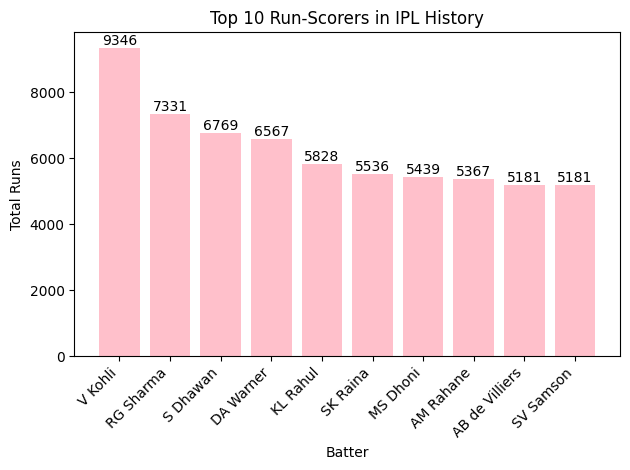

In [56]:
# Your code here
top10 = (df.groupby("batter")["runs_batter"]
           .sum()
           .sort_values(ascending=False)
           .head(10))

fig, ax = plt.subplots()
bars = ax.bar(top10.index, top10.values, color="pink")

ax.set_title("Top 10 Run-Scorers in IPL History")
ax.set_xlabel("Batter")
ax.set_ylabel("Total Runs")
plt.xticks(rotation=45, ha="right")
ax.bar_label(bars)

plt.tight_layout()
plt.show()

**Q13.** Draw a line chart of the total runs scored in each `year`.

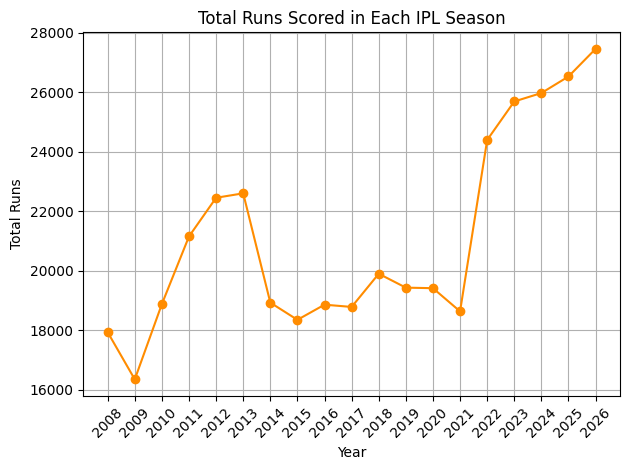

In [57]:
# Your code here
runs_per_year = df.groupby("year")["runs_total"].sum()

fig, ax = plt.subplots()
ax.plot(runs_per_year.index, runs_per_year.values, marker="o", color="darkorange")

ax.set_title("Total Runs Scored in Each IPL Season")
ax.set_xlabel("Year")
ax.set_ylabel("Total Runs")
ax.set_xticks(runs_per_year.index)
plt.xticks(rotation=45)
ax.grid()

plt.tight_layout()
plt.show()

**Q14.** Draw a horizontal bar chart of the number of matches played at the top 10 venues.

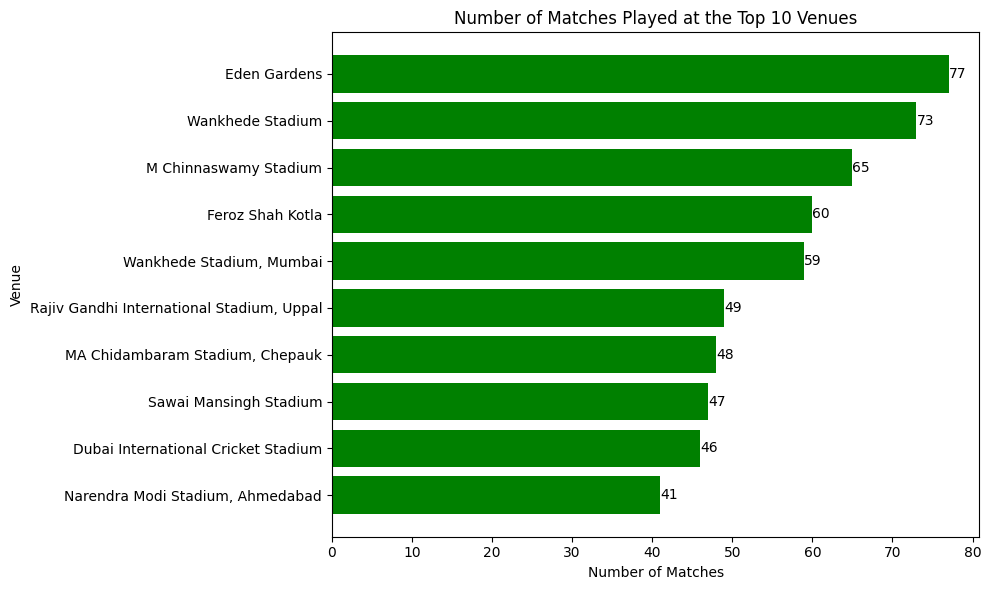

In [58]:
# Your code here
matches_per_venue = (df.groupby("venue")["match_id"]
                     .nunique()
                     .sort_values(ascending=False)
                     .head(10))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(matches_per_venue.index, matches_per_venue.values, color="green")

ax.set_title("Number of Matches Played at the Top 10 Venues")
ax.set_xlabel("Number of Matches")
ax.set_ylabel("Venue")
ax.invert_yaxis()
ax.bar_label(bars)

plt.tight_layout()
plt.show()

**Q15.** Draw a pie chart of the `toss_decision` split (bat vs field).

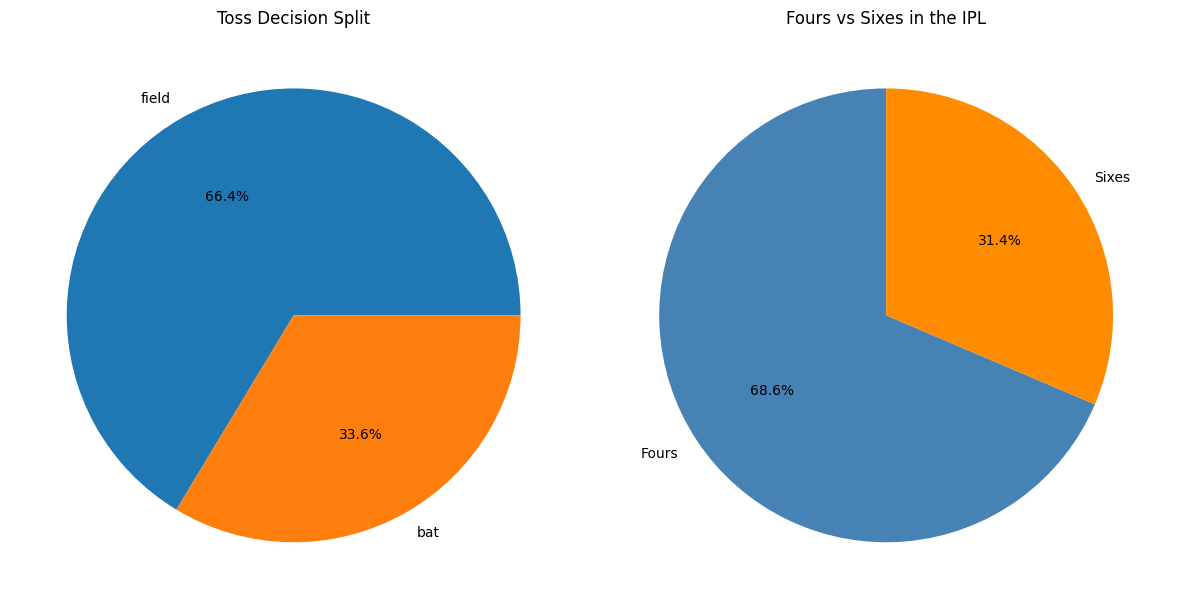

In [59]:

toss_decision_counts = df["toss_decision"].value_counts()
boundaries = df[
    df["runs_batter"].isin([4, 6]) &
    ~df["runs_not_boundary"]
]

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].pie(
    toss_decision_counts.values,
    labels=toss_decision_counts.index,
    autopct="%1.1f%%"
)
ax[0].set_title("Toss Decision Split")

counts = boundaries["runs_batter"].value_counts().reindex([4, 6], fill_value=0)

ax[1].pie(
    counts.values,
    labels=["Fours", "Sixes"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "darkorange"]
)
ax[1].set_title("Fours vs Sixes in the IPL")

plt.tight_layout()
plt.show()


**Q16.** Plot a histogram of `team_runs` at the end of innings 1, using 20 bins.

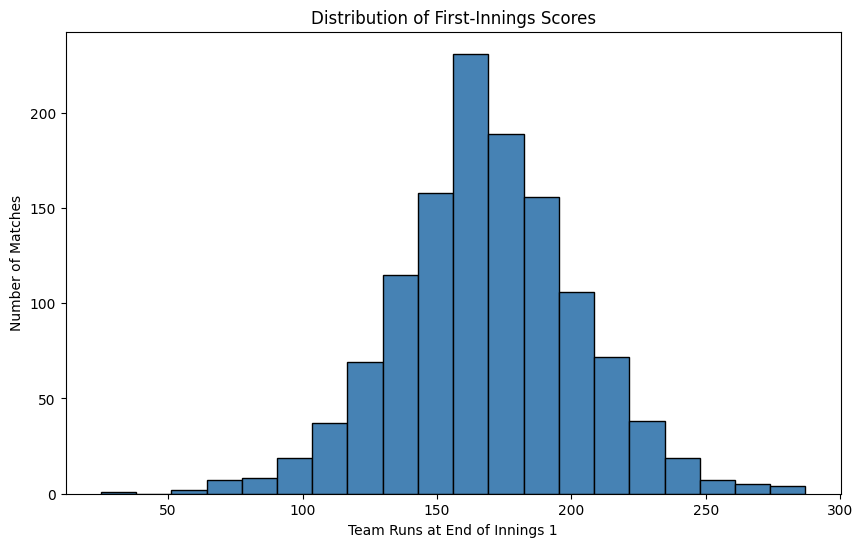

In [60]:
# Your code here
innings1 = df[df["innings"] == 1]

first_innings_score = innings1.groupby("match_id")["team_runs"].max()

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(first_innings_score, bins=20, color="steelblue", edgecolor="black")

ax.set_title("Distribution of First-Innings Scores")
ax.set_xlabel("Team Runs at End of Innings 1")
ax.set_ylabel("Number of Matches")


plt.show()


---
## Beginner Level: Seaborn

**Q17.** Use `sns.countplot` to show how many times each `wicket_kind` occurred.

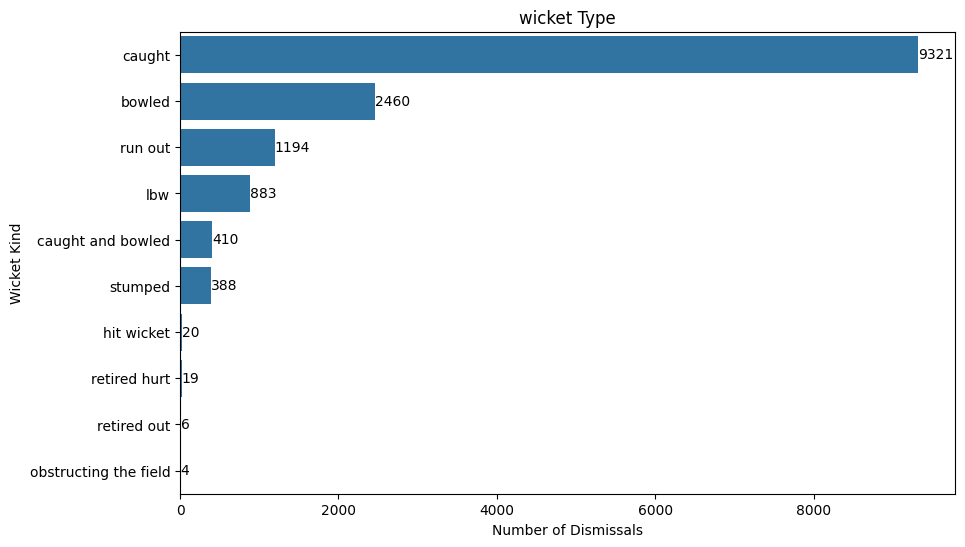

In [61]:
# Your code here
order = df["wicket_kind"].value_counts().index

fig, ax = plt.subplots(figsize=(10, 6))
sns.countplot(data=df, y="wicket_kind", order=order, ax=ax)

ax.set_title("wicket Type")
ax.set_xlabel("Number of Dismissals")
ax.set_ylabel("Wicket Kind")
ax.bar_label(ax.containers[0])

plt.show()

**Q18.** Use `sns.barplot` to show the total runs scored by each `batting_team`.

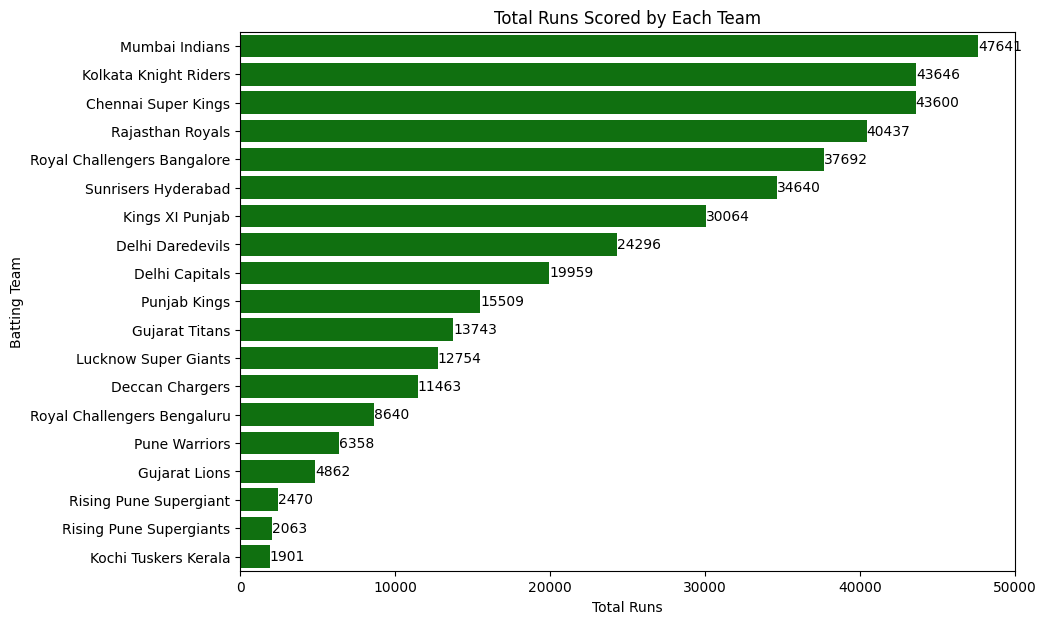

In [62]:
# Your code here
team_runs = (df.groupby("batting_team")["runs_total"].sum().sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=team_runs.values, y=team_runs.index, ax=ax,color="green")

ax.set_title("Total Runs Scored by Each Team")
ax.set_xlabel("Total Runs")
ax.set_ylabel("Batting Team")
ax.bar_label(ax.containers[0])
plt.show()

**Q19.** Use `sns.histplot` with `kde=True` to show the distribution of total runs per match.

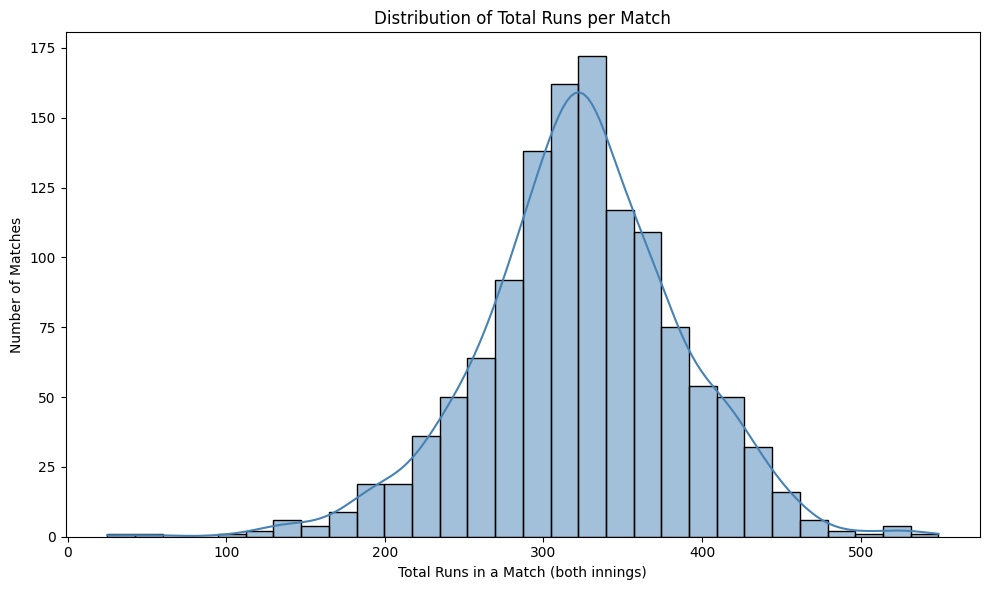

In [63]:
# Your code here
runs_per_match = df.groupby("match_id")["runs_total"].sum()

fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(runs_per_match, kde=True, bins=30, color="steelblue", ax=ax)

ax.set_title("Distribution of Total Runs per Match")
ax.set_xlabel("Total Runs in a Match (both innings)")
ax.set_ylabel("Number of Matches")

plt.tight_layout()
plt.show()

**Q20.** Use `sns.boxplot` to compare the distribution of first-innings scores across seasons, using `year` on the x-axis.

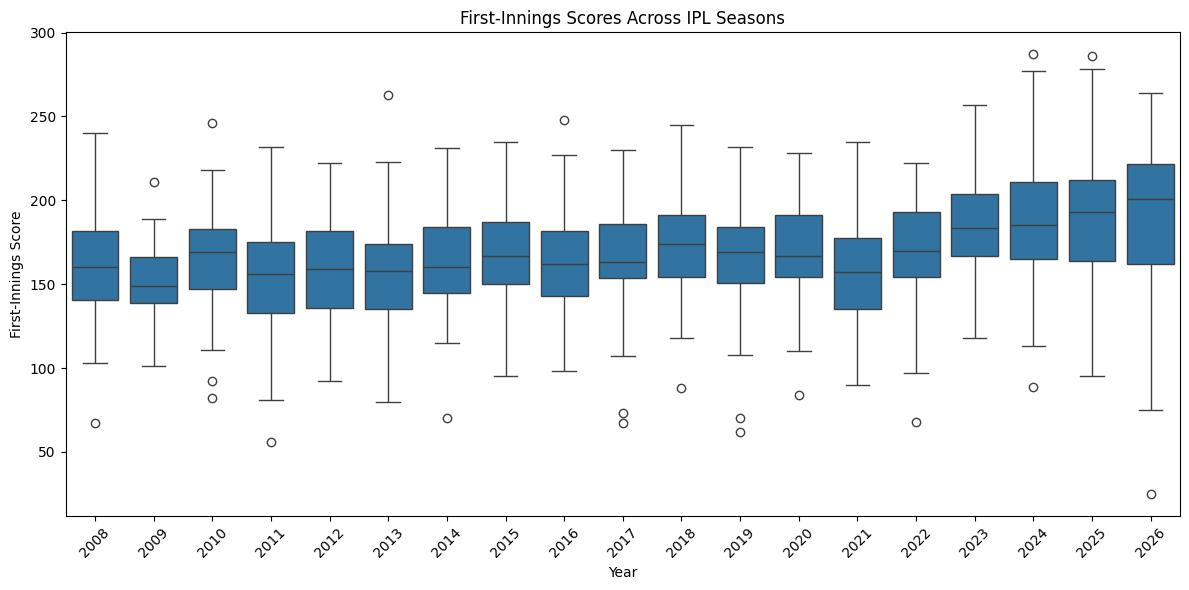

In [64]:
# Your code here
first_innings = (df[df["innings"] == 1].groupby(["match_id", "year"])["team_runs"].max().reset_index(name="first_innings_score"))

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=first_innings, x="year", y="first_innings_score", ax=ax)

ax.set_title("First-Innings Scores Across IPL Seasons")
ax.set_xlabel("Year")
ax.set_ylabel("First-Innings Score")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

---
## Medium Level

**Q21.** **Strike rate and average.** For batters with at least 1,000 balls faced, calculate runs, balls faced (`valid_ball == 1`) and strike rate. Plot a seaborn scatterplot of strike rate vs total runs. Label the top 5 players with `plt.annotate`.

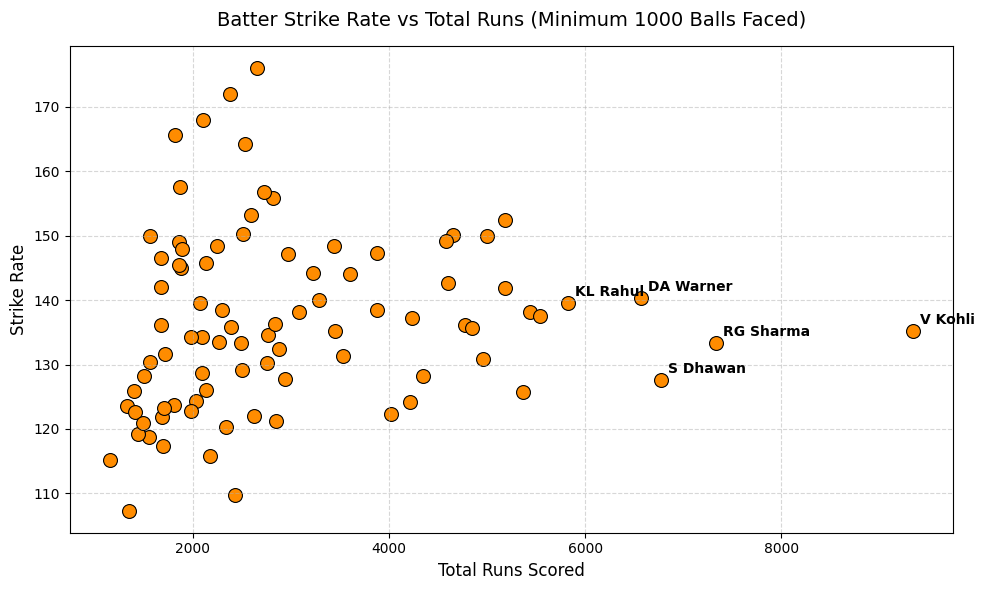

In [65]:
runs = df.groupby("batter")["runs_batter"].sum()
valid = df[df["valid_ball"] == 1]
balls = valid.groupby("batter")["valid_ball"].count()

data = pd.DataFrame({"runs": runs, "balls": balls})
data = data[data["balls"] >= 1000].reset_index()
data["strike_rate"] = (data["runs"] / data["balls"]) * 100

top_n = min(5, len(data))
top_batters = data.sort_values("runs", ascending=False).head(top_n)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x="runs", y="strike_rate", color="darkorange", s=100, edgecolor="black")

for idx, row in top_batters.iterrows():
    plt.annotate(row["batter"], (row["runs"], row["strike_rate"]), xytext=(5, 5), textcoords="offset points", fontsize=10, weight="bold")

plt.title("Batter Strike Rate vs Total Runs (Minimum 1000 Balls Faced)", fontsize=14, pad=15)
plt.xlabel("Total Runs Scored", fontsize=12)
plt.ylabel("Strike Rate", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Q22.** **Phase analysis.** Create a column `phase` using `np.select`: Powerplay is overs 0-5, Middle is 6-14 and Death is 15-19. Then draw a grouped bar chart (`sns.barplot` with `hue`) of the average runs per over in each phase, split by `year`.

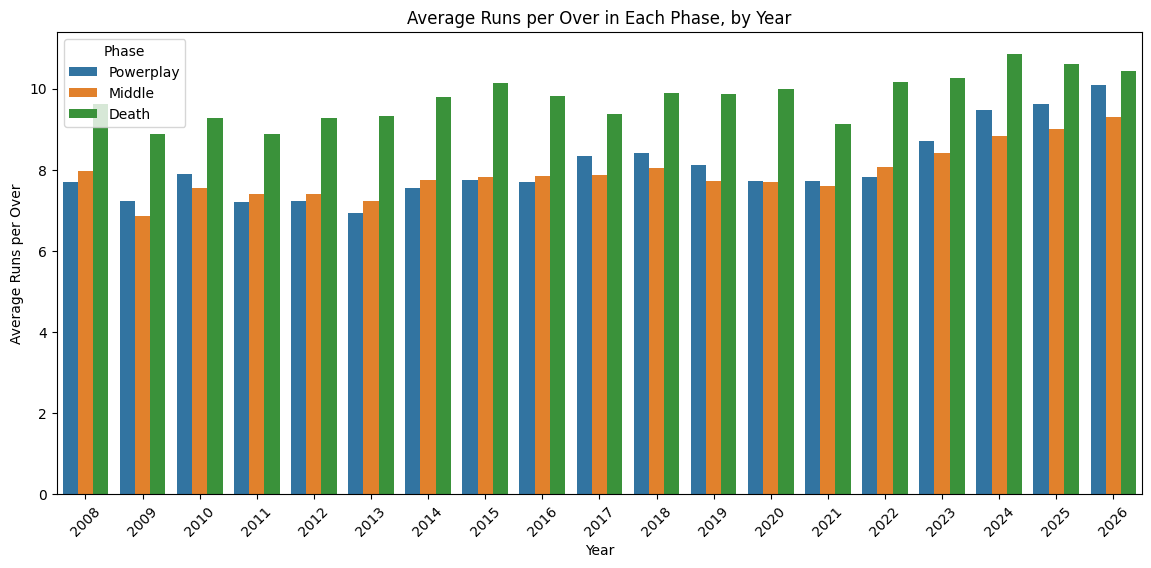

In [66]:
# Your code here
data = df[df["innings"].isin([1, 2])]

overs = data.groupby(["match_id", "innings", "over", "year"])["runs_total"].sum().reset_index()

conditions = [
    overs["over"] <= 5,
    (overs["over"] >= 6) & (overs["over"] <= 14),
    overs["over"] >= 15
]
names = ["Powerplay", "Middle", "Death"]

overs["phase"] = np.select(conditions, names, default="Other")

plt.figure(figsize=(14, 6))
sns.barplot(data=overs, x="year", y="runs_total", hue="phase",
            hue_order=["Powerplay", "Middle", "Death"], errorbar=None)

plt.title("Average Runs per Over in Each Phase, by Year")
plt.xlabel("Year")
plt.ylabel("Average Runs per Over")
plt.xticks(rotation=45)
plt.legend(title="Phase")
plt.show()

**Q23.** **Toss impact.** For each match, find whether the toss winner also won the match (`toss_winner == match_won_by`). Compute the win percentage of toss winners per season and plot it as a line chart with a horizontal reference line at 50%.

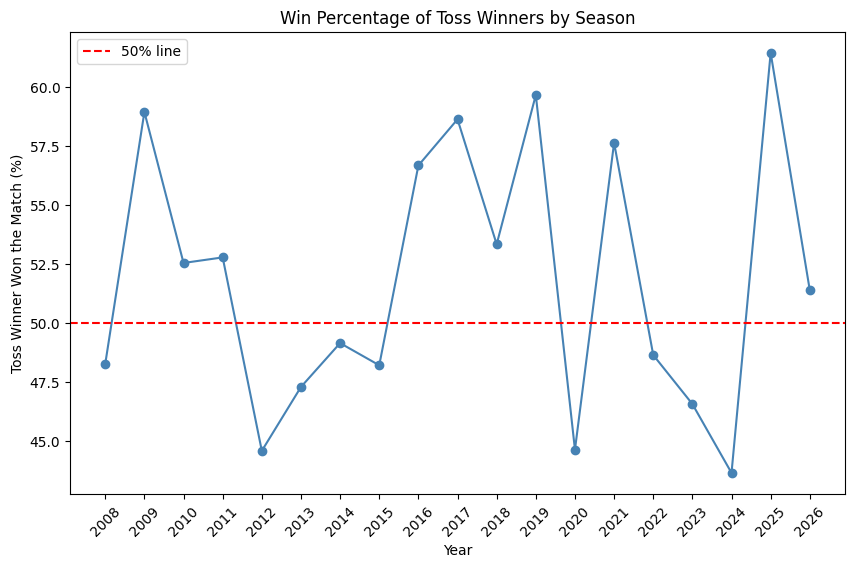

In [67]:
# Your code here
matches = df.drop_duplicates("match_id")
matches = matches[["match_id", "year", "toss_winner", "match_won_by"]].copy()

matches = matches[matches["match_won_by"] != "Unknown"]

matches["toss_won_match"] = matches["toss_winner"] == matches["match_won_by"]

toss_pct = matches.groupby("year")["toss_won_match"].mean() * 100

plt.figure(figsize=(10, 6))
plt.plot(toss_pct.index, toss_pct.values, marker="o", color="steelblue")
plt.axhline(50, color="red", linestyle="--", label="50% line")

plt.title("Win Percentage of Toss Winners by Season")
plt.xlabel("Year")
plt.ylabel("Toss Winner Won the Match (%)")
plt.xticks(toss_pct.index, rotation=45)
plt.legend()
plt.show()

**Q24.** **Heatmap.** Build a pivot table of `batting_team` against `year` with total runs as values. Draw it with `sns.heatmap` using `annot=True`. Merge the renamed franchises first (e.g. "Delhi Daredevils" and "Delhi Capitals") so each team has one row.

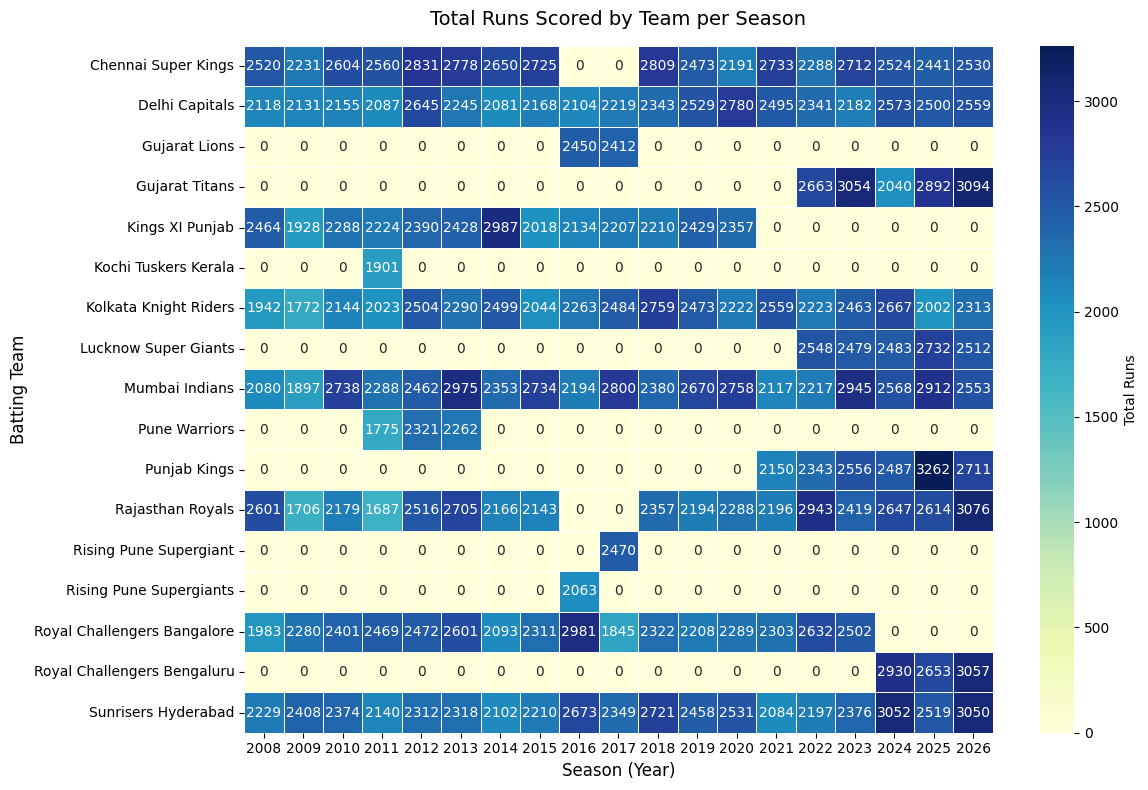

In [68]:
df_clean = df.copy()

franchise_map = {
    "Delhi Daredevils": "Delhi Capitals",
    "Deccan Chargers": "Sunrisers Hyderabad"
}
df_clean["batting_team"] = df_clean["batting_team"].replace(franchise_map)

pivot_table = df_clean.pivot_table(
    values="runs_total",
    index="batting_team",
    columns="year",
    aggfunc="sum",
    fill_value=0
)

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_table, annot=True, fmt="g", cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "Total Runs"})

plt.title("Total Runs Scored by Team per Season", fontsize=14, pad=15)
plt.xlabel("Season (Year)", fontsize=12)
plt.ylabel("Batting Team", fontsize=12)
plt.tight_layout()
plt.show()

**Q25.** **Dashboard.** Using `plt.subplots(2, 2)`, make one figure with four plots for one batter of your choice (e.g. "V Kohli"): runs per season (bar), runs-per-ball distribution (count of 0s, 1s, 2s, 4s and 6s), dismissal types (pie), and the over in which he scores most (line).

/tmp/ipykernel_1678/2484327369.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=runs_season.index, y=runs_season.values, ax=axes[0, 0], palette="Blues_d")
/tmp/ipykernel_1678/2484327369.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=runs_dist.index, y=runs_dist.values, ax=axes[0, 1], palette="Oranges_d")


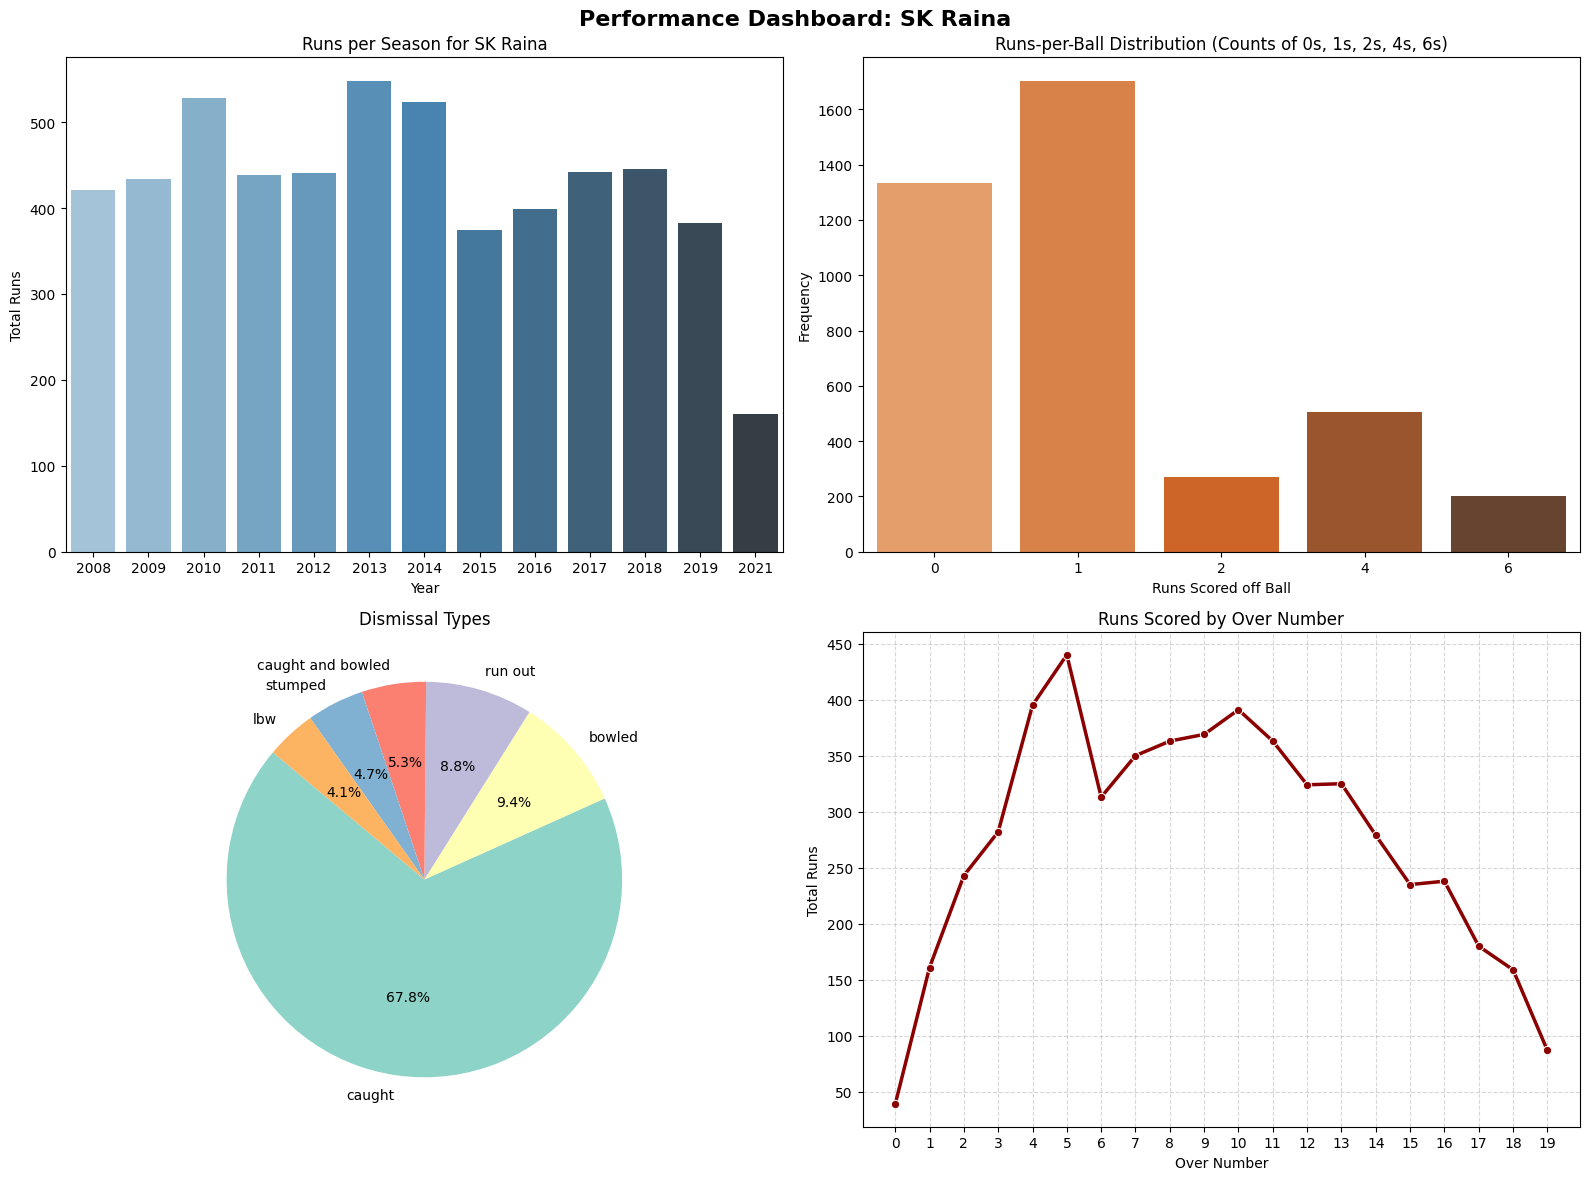

In [69]:
batter_name = "SK Raina"
batter_df = df[df["batter"] == batter_name]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

runs_season = batter_df.groupby("year")["runs_batter"].sum()
sns.barplot(x=runs_season.index, y=runs_season.values, ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title(f"Runs per Season for {batter_name}", fontsize=12)
axes[0, 0].set_xlabel("Year")
axes[0, 0].set_ylabel("Total Runs")

valid_balls = batter_df[batter_df["valid_ball"] == 1]
runs_dist = valid_balls["runs_batter"].value_counts().reindex([0, 1, 2, 4, 6], fill_value=0)
sns.barplot(x=runs_dist.index, y=runs_dist.values, ax=axes[0, 1], palette="Oranges_d")
axes[0, 1].set_title("Runs-per-Ball Distribution (Counts of 0s, 1s, 2s, 4s, 6s)", fontsize=12)
axes[0, 1].set_xlabel("Runs Scored off Ball")
axes[0, 1].set_ylabel("Frequency")

dismissals = df[df["player_out"] == batter_name]["wicket_kind"].value_counts()
axes[1, 0].pie(dismissals.values, labels=dismissals.index, autopct="%1.1f%%", startangle=140, colors=sns.color_palette("Set3"))
axes[1, 0].set_title("Dismissal Types", fontsize=12)

over_runs = batter_df.groupby("over")["runs_batter"].sum()
sns.lineplot(x=over_runs.index, y=over_runs.values, ax=axes[1, 1], marker="o", color="darkred", linewidth=2.5)
axes[1, 1].set_title("Runs Scored by Over Number", fontsize=12)
axes[1, 1].set_xlabel("Over Number")
axes[1, 1].set_ylabel("Total Runs")
axes[1, 1].set_xticks(range(20))
axes[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle(f"Performance Dashboard: {batter_name}", fontsize=16, weight="bold", y=0.98)
plt.tight_layout()
plt.show()